# Credit Card Default Risk Analysis
## CA1 — Payments and Transaction Services (MSCFTD1)

---

## Introduction

This notebook presents a comprehensive credit risk analysis using the **Taiwan Credit Card Default dataset** (UCI/Kaggle NPCI Credit Card Default Risk Analysis), covering **30,000 clients** and their payment behaviour from **April to September 2005**.

### 1. Exploratory Data Analysis (EDA)
A thorough data cleaning and exploratory analysis is conducted, including standardisation of undocumented categorical codes, feature engineering (utilization and payment ratios), and visualisation of demographic, repayment, and billing patterns associated with credit card defaults.

### 2. Machine Learning & Deep Neural Networks
Five traditional machine learning models — **Logistic Regression, Random Forest, Gradient Boosting, SVM, and XGBoost** — are trained and benchmarked against two **Deep Neural Network (DNN)** architectures built in TensorFlow/Keras, to predict the probability of default in the following month. Class imbalance in the target variable is addressed using **SMOTE**, and all models are evaluated using a comprehensive set of metrics (Accuracy, AUC, F1-Score, Recall, Precision, Specificity, KS Statistic, Balanced Accuracy, MCC, and G-Mean).

### 3. Theory of Credit Card Profits & Loan Provisioning
A structured discussion connects the economic mechanics of credit card profitability — net interest margin, interchange fees, and revolving credit dynamics — to how predictive model outputs are practically used by financial institutions for loan provisioning, automated credit scoring, and safeguarding portfolio profitability.

---

#**Student:** Vaibhav Pawar
#**Module:** Payments and Transaction Services (MSCFTD1)
#**Institution:** National College of Ireland
#**Dataset:** default_of_credit_card_clients.csv (30,000 clients, Taiwan, 2005)

## Import Libraries

In this section, we import the necessary Python libraries required for data manipulation, visualization, machine learning, and deep learning:

* pandas – for data manipulation and analysis
* numpy – for numerical computations
* matplotlib – for creating static visualizations
* seaborn – for advanced statistical visualizations
* scikit-learn (sklearn) – for building and evaluating traditional machine learning models: train_test_split, StandardScaler, LogisticRegression, RandomForestClassifier, GradientBoostingClassifier, SVC, accuracy_score, roc_auc_score, f1_score, recall_score, precision_score, confusion_matrix, matthews_corrcoef, balanced_accuracy_score, roc_curve
* scipy.stats (ks_2samp) – to compute the Kolmogorov-Smirnov statistic for model evaluation
* imbalanced-learn (SMOTE) – to address class imbalance in the target variable
* xgboost (XGBClassifier) – gradient boosting model
* tensorflow / keras – to build and train the Deep Neural Network models

In [471]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, recall_score,
                              precision_score, confusion_matrix, matthews_corrcoef,
                              balanced_accuracy_score)
from scipy.stats import ks_2samp
from sklearn.metrics import roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization

## Load Dataset

We load the **default_of_credit_card_clients** dataset directly from the working directory. This dataset contains **30,000 credit card clients** from Taiwan, along with demographic details, repayment history, billing amounts, and the target variable indicating default status.

In [415]:
df = pd.read_csv('default_of_credit_card_clients.csv')

## Initial Data Exploration

Before cleaning the data, we perform a quick initial inspection to understand the structure of the dataset:

- **Shape** – total number of rows (clients) and columns (features)
- **Columns** – list of all available features in the dataset
- **First 5 rows** – a preview of the raw data to understand its format and content

In [416]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
df.head()

Shape: (30000, 25)

Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

First 5 rows:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Data Cleaning – Missing Values & Duplicates Check

Before making any changes to the dataset, we check for **missing values** and **duplicate rows** to confirm the data is clean and reliable for further processing.

In [417]:
print("Missing values:\n", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 0
Duplicate rows: 0


## Data Cleaning – EDUCATION Standardisation

The **EDUCATION** column contains undocumented codes (`0`, `5`, `6`) alongside the official categories (1 = Grad School, 2 = University, 3 = High School, 4 = Others). We merge these undocumented codes into the existing **Others (4)** category to keep the feature consistent with its documented scheme.

In [418]:
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

## Data Cleaning – MARRIAGE Standardisation

The **MARRIAGE** column contains an undocumented code (`0`) alongside the official categories (1 = Married, 2 = Single, 3 = Others). We merge this undocumented code into the existing **Others (3)** category to keep the feature consistent with its documented scheme.

In [419]:
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

## Data Cleaning – Rename PAY_0 to PAY_1

The repayment status columns are inconsistently named in the original dataset (`PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6`), skipping `PAY_1`. We rename **PAY_0** to **PAY_1** so the columns follow a logical sequence from PAY_1 (September) to PAY_6 (April).

In [420]:
df.rename(columns={'PAY_0': 'PAY_1'}, inplace=True)

## Data Cleaning – Verification

We verify that the **EDUCATION** and **MARRIAGE** columns have been correctly standardised by checking their updated value counts.

In [421]:
print("\nEDUCATION values:\n", df['EDUCATION'].value_counts())
print("\nMARRIAGE values:\n", df['MARRIAGE'].value_counts())


EDUCATION values:
 EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64

MARRIAGE values:
 MARRIAGE
2    15964
1    13659
3      377
Name: count, dtype: int64


## Data Cleaning – Final Verification

We perform a final verification pass to confirm the dataset is correctly structured before proceeding to EDA:

- **Column info** – confirming data types and non-null counts across all columns
- **EDUCATION and MARRIAGE values** – confirming the standardisation was applied correctly
- **Columns** – confirming the full list of features, including the renamed PAY_1 column

In [422]:
df.info()
print("\nEDUCATION values:\n", df['EDUCATION'].value_counts())
print("\nMARRIAGE values:\n", df['MARRIAGE'].value_counts())
print("\nColumns:", df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_1                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

## Data Cleaning – Rename Target Column

The target column **default payment next month** contains spaces, making it awkward to reference in code. We rename it to **default** for cleaner and more readable code throughout the notebook.

In [423]:
df.rename(columns={'default payment next month': 'default'}, inplace=True)

## Data Cleaning – Labelled Categorical Columns

We create labelled versions of the categorical columns (**SEX_LABEL**, **EDUCATION_LABEL**, **MARRIAGE_LABEL**) to make visualisations and summary statistics more interpretable, while retaining the original numeric-coded columns for modelling.

In [424]:
df['SEX_LABEL'] = df['SEX'].map({1: 'Male', 2: 'Female'})

df['EDUCATION_LABEL'] = df['EDUCATION'].map({1: 'Grad School', 2: 'University', 3: 'High School', 4: 'Others'})

df['MARRIAGE_LABEL'] = df['MARRIAGE'].map({1: 'Married', 2: 'Single', 3: 'Others'})

## Data Cleaning – Drop ID Column

The **ID** column is a unique row identifier with no predictive value. We drop it from the dataset to prevent it from being accidentally included in any analysis or modelling steps.

In [425]:
df.drop(columns=['ID'], inplace=True)

## EDA – Target Class Distribution

We examine the distribution of the target variable **default** to understand the class balance in the dataset. This helps determine whether the dataset is imbalanced and informs the modelling strategy in later sections.

In [426]:
print(df['default'].value_counts())
print("\nDefault Rate (%):\n", df['default'].value_counts(normalize=True) * 100)

default
0    23364
1     6636
Name: count, dtype: int64

Default Rate (%):
 default
0    77.88
1    22.12
Name: proportion, dtype: float64


## Visualisation – Target Class Distribution

This bar chart visualises the distribution of the **default** target variable, highlighting the class imbalance between clients who defaulted and those who did not.

/tmp/ipykernel_3679/3147744582.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='default', data=df, palette=['#2e86ab', '#c73e1d'])


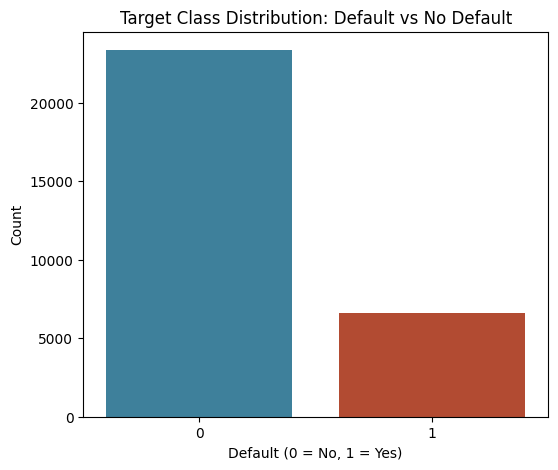

In [427]:
plt.figure(figsize=(6, 5))
sns.countplot(x='default', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Target Class Distribution: Default vs No Default')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.savefig('viz_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Default by Gender

This bar chart visualises the distribution of default status across genders, showing the count of defaulters and non-defaulters for males and females.

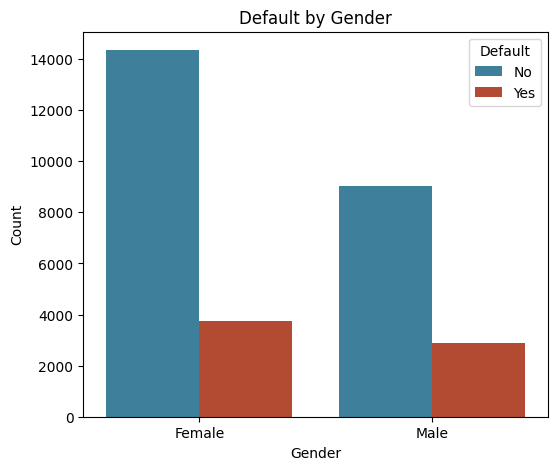

In [428]:
plt.figure(figsize=(6, 5))
sns.countplot(x='SEX_LABEL', hue='default', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Default by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Default', labels=['No', 'Yes'])
plt.savefig('viz_default_by_gender.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Default by Education Level

This bar chart visualises the distribution of default status across education levels, showing the count of defaulters and non-defaulters for each category.

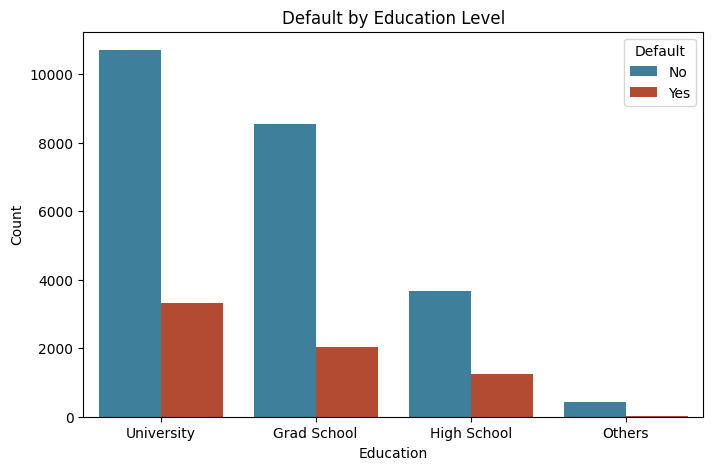

In [429]:
plt.figure(figsize=(8, 5))
sns.countplot(x='EDUCATION_LABEL', hue='default', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Default by Education Level')
plt.xlabel('Education')
plt.ylabel('Count')
plt.legend(title='Default', labels=['No', 'Yes'])
plt.savefig('viz_default_by_education.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Default by Marital Status

This bar chart visualises the distribution of default status across marital status categories, showing the count of defaulters and non-defaulters for each group.

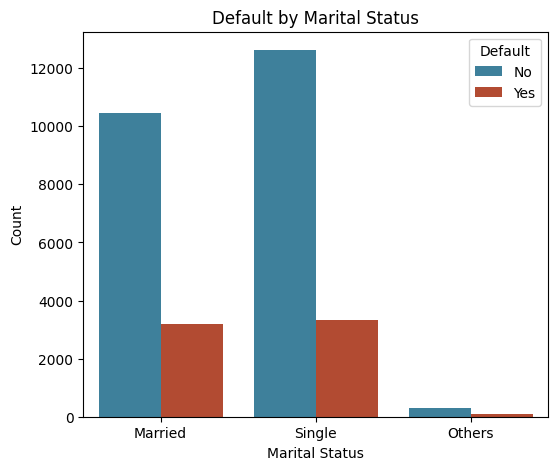

In [430]:
plt.figure(figsize=(6, 5))
sns.countplot(x='MARRIAGE_LABEL', hue='default', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Default by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Count')
plt.legend(title='Default', labels=['No', 'Yes'])
plt.savefig('viz_default_by_marriage.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Age Distribution by Default Status

This histogram visualises the distribution of client age, layered by default status, to examine whether age influences the likelihood of default.

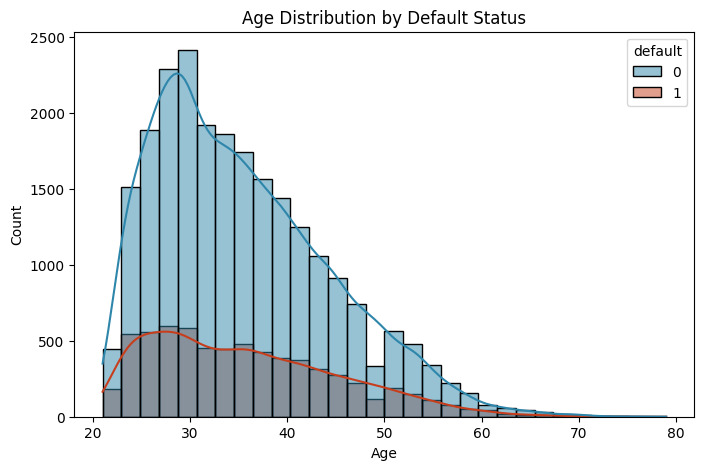

In [431]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='AGE', hue='default', bins=30, kde=True, palette=['#2e86ab', '#c73e1d'], multiple='layer')
plt.title('Age Distribution by Default Status')
plt.xlabel('Age')
plt.ylabel('Count')
plt.savefig('viz_default_by_age.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Credit Limit Distribution by Default Status

This histogram visualises the distribution of client credit limits, layered by default status, to examine whether credit limit influences the likelihood of default.

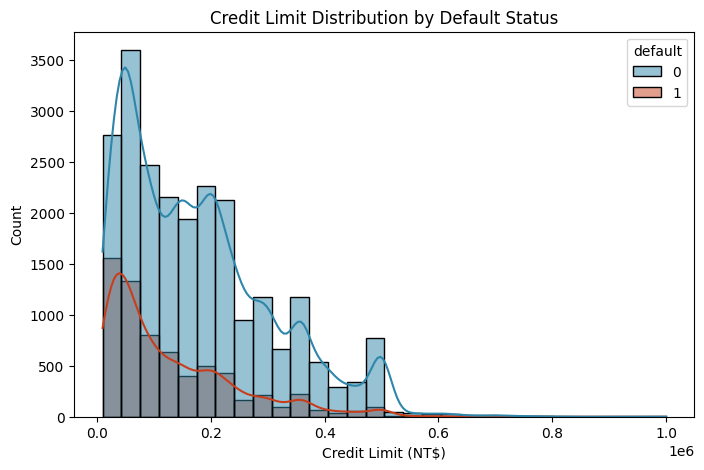

In [432]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='LIMIT_BAL', hue='default', bins=30, kde=True, palette=['#2e86ab', '#c73e1d'], multiple='layer')
plt.title('Credit Limit Distribution by Default Status')
plt.xlabel('Credit Limit (NT$)')
plt.ylabel('Count')
plt.savefig('viz_default_by_limit_bal.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Default by Repayment Status (PAY_1)

This bar chart visualises the distribution of default status across repayment status categories for September (PAY_1), the most recent billing cycle in the dataset.

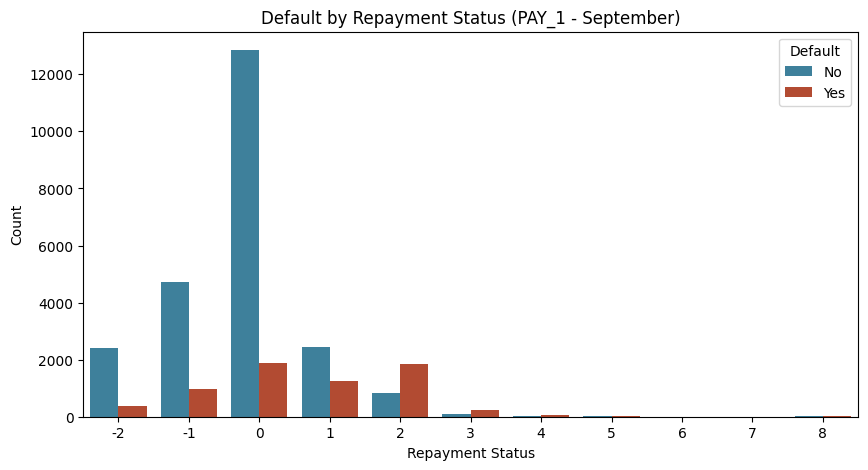

In [433]:
plt.figure(figsize=(10, 5))
sns.countplot(x='PAY_1', hue='default', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Default by Repayment Status (PAY_1 - September)')
plt.xlabel('Repayment Status')
plt.ylabel('Count')
plt.legend(title='Default', labels=['No', 'Yes'])
plt.savefig('viz_default_by_pay1.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Bill Amount by Default Status

This box plot visualises the distribution of the September bill amount (BILL_AMT1) across default status, highlighting the spread and outliers for each group.

/tmp/ipykernel_3679/2455942733.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='default', y='BILL_AMT1', data=df, palette=['#2e86ab', '#c73e1d'])


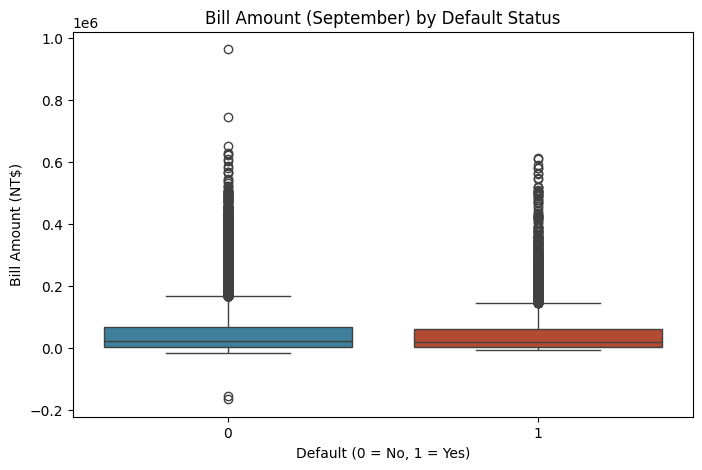

In [434]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='default', y='BILL_AMT1', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Bill Amount (September) by Default Status')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Bill Amount (NT$)')
plt.savefig('viz_default_by_bill_amt1.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Payment Amount by Default Status

This box plot visualises the distribution of the September payment amount (PAY_AMT1) across default status, highlighting the spread and outliers for each group.

/tmp/ipykernel_3679/3801869610.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='default', y='PAY_AMT1', data=df, palette=['#2e86ab', '#c73e1d'])


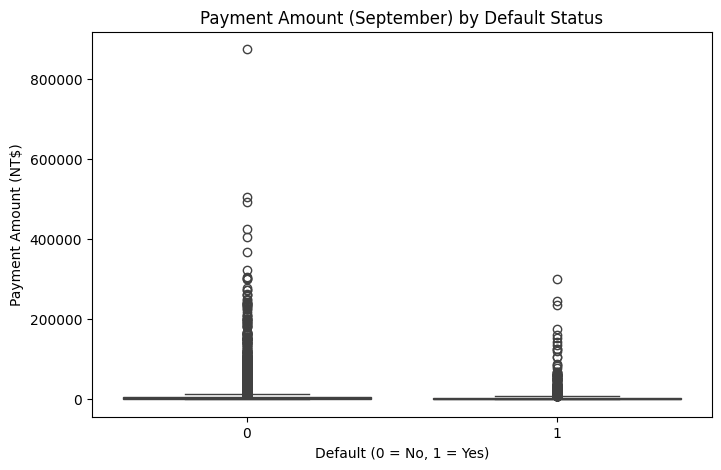

In [435]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='default', y='PAY_AMT1', data=df, palette=['#2e86ab', '#c73e1d'])
plt.title('Payment Amount (September) by Default Status')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Payment Amount (NT$)')
plt.savefig('viz_default_by_pay_amt1.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Correlation Heatmap

This heatmap visualises the pairwise correlation between all numeric features in the dataset, helping to identify strong relationships and potential multicollinearity, particularly among the repayment status and bill amount columns.

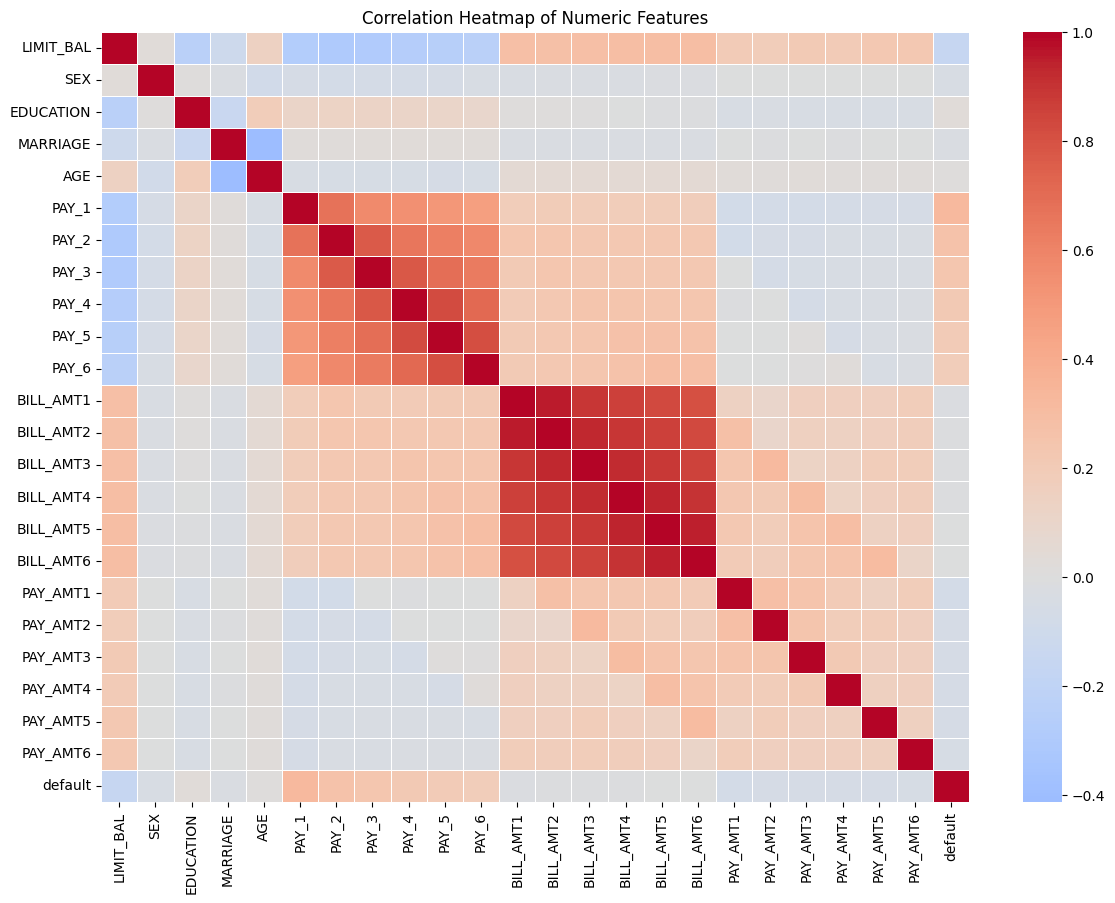

In [436]:
plt.figure(figsize=(14, 10))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.savefig('viz_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## Feature Engineering – Utilization & Payment Ratios

We create two engineered features to capture credit risk behaviour more directly:

- **UTILIZATION_RATIO** – the proportion of the credit limit currently used (BILL_AMT1 / LIMIT_BAL)
- **PAYMENT_RATIO** – the proportion of the bill amount actually paid (PAY_AMT1 / BILL_AMT1)

Division by zero cases are handled by replacing zero denominators with NaN, then filling the resulting missing values with 0.

In [437]:
df['UTILIZATION_RATIO'] = df['BILL_AMT1'] / df['LIMIT_BAL'].replace(0, np.nan)
df['PAYMENT_RATIO'] = df['PAY_AMT1'] / df['BILL_AMT1'].replace(0, np.nan)
df['UTILIZATION_RATIO'] = df['UTILIZATION_RATIO'].fillna(0)
df['PAYMENT_RATIO'] = df['PAYMENT_RATIO'].fillna(0)

## Train/Test Split & Feature Scaling

We split the dataset into training (80%) and testing (20%) sets using stratified sampling to preserve the class distribution of the target variable. The labelled string columns (SEX_LABEL, EDUCATION_LABEL, MARRIAGE_LABEL) are excluded from the feature set, as they are duplicates of already-encoded numeric columns.

**StandardScaler** is then applied to standardise all numeric features to zero mean and unit variance, which is important for distance-based and gradient-based models such as SVM and the Deep Neural Network.

In [438]:
X = df.drop(columns=['default', 'SEX_LABEL', 'EDUCATION_LABEL', 'MARRIAGE_LABEL'])
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (24000, 25)
Testing set size: (6000, 25)


## Handling Class Imbalance – SMOTE

The dataset shows a class imbalance in the target variable, with defaults (22.1%) significantly underrepresented compared to non-defaults (77.9%). We apply **SMOTE (Synthetic Minority Oversampling Technique)** to the training set only, generating synthetic samples of the minority class to achieve a balanced 50/50 class distribution. This prevents the models from being biased towards predicting the majority class, while keeping the test set untouched to preserve a realistic evaluation of real-world performance.

In [439]:
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_balanced.value_counts().to_dict())

Before SMOTE: {0: 18691, 1: 5309}
After SMOTE: {0: 18691, 1: 18691}


## Shuffle Balanced Training Data

SMOTE appends synthetic minority-class samples to the end of the training data, which can cause Keras's `validation_split` to draw an unrepresentative validation set. We shuffle the balanced training data to ensure a proper, representative split during DNN training.

In [440]:
from sklearn.utils import shuffle

X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=42)

## Model 1 – Logistic Regression

We train a **Logistic Regression** model as the baseline classifier, using the SMOTE-balanced training data. Predictions and predicted probabilities are generated on the scaled test set for evaluation.

In [441]:
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_balanced, y_train_balanced)

y_pred_log_reg = log_reg.predict(X_test_scaled)
y_proba_log_reg = log_reg.predict_proba(X_test_scaled)[:, 1]

## Model Evaluation Function & Logistic Regression Results

We define a reusable **evaluate_model** function to consistently assess every model built in this notebook using a comprehensive set of classification metrics: Accuracy, AUC, F1-Score, Recall, Precision, Specificity, KS Statistic, Balanced Accuracy, Matthews Correlation Coefficient (MCC), G-Mean, and the Confusion Matrix. This function is applied to the Logistic Regression model to generate its evaluation results.

In [442]:
def evaluate_model(y_true, y_pred, y_proba, model_name):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    specificity = tn / (tn + fp)
    sensitivity = tp / (tp + fn)
    g_mean = np.sqrt(sensitivity * specificity)

    ks_stat = ks_2samp(y_proba[y_true == 1], y_proba[y_true == 0]).statistic

    results = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'AUC': roc_auc_score(y_true, y_proba),
        'F1-Score': f1_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Specificity': specificity,
        'KS Statistic': ks_stat,
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'MCC': matthews_corrcoef(y_true, y_pred),
        'G-Mean': g_mean
    }

    print(f"\n{'='*50}")
    print(f"{model_name} - Evaluation Results")
    print(f"{'='*50}")
    for key, val in results.items():
        if key != 'Model':
            print(f"{key:<20}: {val:.4f}")

    print(f"\nConfusion Matrix:\n{cm}")

    return results

log_reg_results = evaluate_model(y_test, y_pred_log_reg, y_proba_log_reg, 'Logistic Regression')


Logistic Regression - Evaluation Results
Accuracy            : 0.6878
AUC                 : 0.7137
F1-Score            : 0.4662
Recall              : 0.6164
Precision           : 0.3749
Specificity         : 0.7081
KS Statistic        : 0.3578
Balanced Accuracy   : 0.6623
MCC                 : 0.2800
G-Mean              : 0.6607

Confusion Matrix:
[[3309 1364]
 [ 509  818]]


## Visualisation – Confusion Matrix (Logistic Regression)

This heatmap visualises the confusion matrix for the Logistic Regression model, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

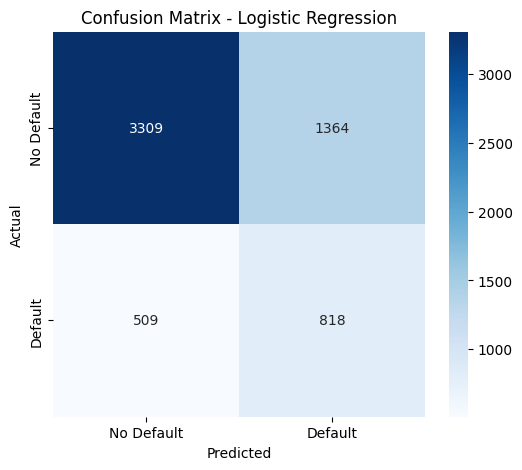

In [443]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_log_reg)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_log_reg.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (Logistic Regression)

This chart visualises the ROC curve for the Logistic Regression model, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

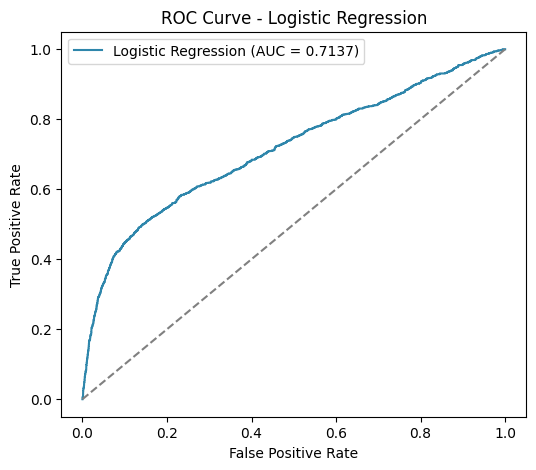

In [444]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_log_reg)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'Logistic Regression (AUC = {log_reg_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_log_reg.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 2 – Random Forest

We train a **Random Forest** classifier using the SMOTE-balanced training data. Predictions and predicted probabilities are generated on the scaled test set, and the model is evaluated using the same set of metrics as Logistic Regression.

In [445]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_balanced, y_train_balanced)

y_pred_rf = rf.predict(X_test_scaled)
y_proba_rf = rf.predict_proba(X_test_scaled)[:, 1]

rf_results = evaluate_model(y_test, y_pred_rf, y_proba_rf, 'Random Forest')


Random Forest - Evaluation Results
Accuracy            : 0.7920
AUC                 : 0.7471
F1-Score            : 0.4943
Recall              : 0.4597
Precision           : 0.5346
Specificity         : 0.8864
KS Statistic        : 0.3883
Balanced Accuracy   : 0.6730
MCC                 : 0.3660
G-Mean              : 0.6383

Confusion Matrix:
[[4142  531]
 [ 717  610]]


## Visualisation – Confusion Matrix (Random Forest)

This heatmap visualises the confusion matrix for the Random Forest model, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

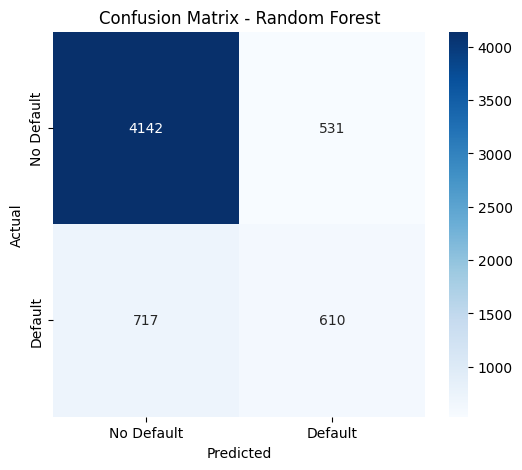

In [446]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_rf.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (Random Forest)

This chart visualises the ROC curve for the Random Forest model, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

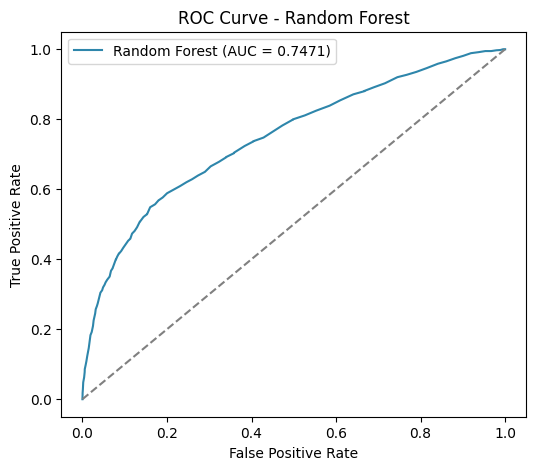

In [447]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_rf)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'Random Forest (AUC = {rf_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - Random Forest')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_rf.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 3 – Gradient Boosting

We train a **Gradient Boosting** classifier using the SMOTE-balanced training data. Predictions and predicted probabilities are generated on the scaled test set, and the model is evaluated using the same set of metrics as the previous models.

In [448]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_balanced, y_train_balanced)

y_pred_gb = gb.predict(X_test_scaled)
y_proba_gb = gb.predict_proba(X_test_scaled)[:, 1]

gb_results = evaluate_model(y_test, y_pred_gb, y_proba_gb, 'Gradient Boosting')


Gradient Boosting - Evaluation Results
Accuracy            : 0.7920
AUC                 : 0.7681
F1-Score            : 0.5121
Recall              : 0.4936
Precision           : 0.5321
Specificity         : 0.8767
KS Statistic        : 0.4030
Balanced Accuracy   : 0.6852
MCC                 : 0.3806
G-Mean              : 0.6578

Confusion Matrix:
[[4097  576]
 [ 672  655]]


## Visualisation – Confusion Matrix (Gradient Boosting)

This heatmap visualises the confusion matrix for the Gradient Boosting model, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

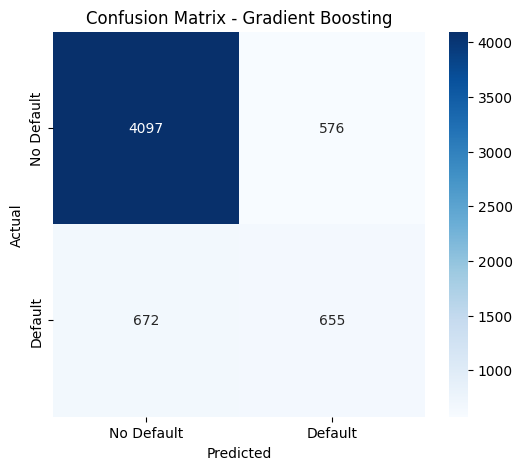

In [449]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - Gradient Boosting')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_gb.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (Gradient Boosting)

This chart visualises the ROC curve for the Gradient Boosting model, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

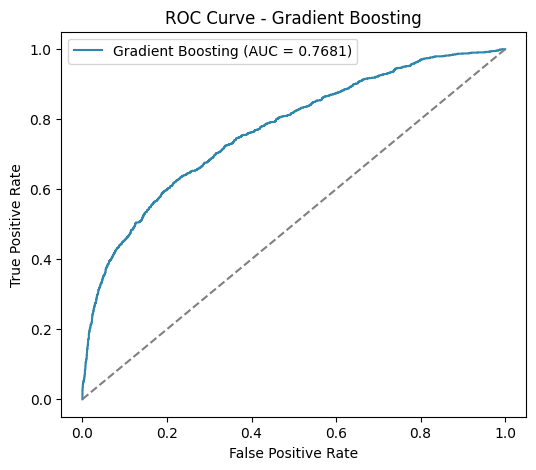

In [450]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_gb)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'Gradient Boosting (AUC = {gb_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - Gradient Boosting')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_gb.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 4 – SVM

We train a **Support Vector Machine (SVM)** classifier with probability estimates enabled, using the SMOTE-balanced training data. Predictions and predicted probabilities are generated on the scaled test set, and the model is evaluated using the same set of metrics as the previous models.

In [451]:
svm = SVC(probability=True, random_state=42)
svm.fit(X_train_balanced, y_train_balanced)

y_pred_svm = svm.predict(X_test_scaled)
y_proba_svm = svm.predict_proba(X_test_scaled)[:, 1]

svm_results = evaluate_model(y_test, y_pred_svm, y_proba_svm, 'SVM')


SVM - Evaluation Results
Accuracy            : 0.7815
AUC                 : 0.7525
F1-Score            : 0.5252
Recall              : 0.5463
Precision           : 0.5056
Specificity         : 0.8483
KS Statistic        : 0.3972
Balanced Accuracy   : 0.6973
MCC                 : 0.3840
G-Mean              : 0.6808

Confusion Matrix:
[[3964  709]
 [ 602  725]]


## Visualisation – Confusion Matrix (SVM)

This heatmap visualises the confusion matrix for the SVM model, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

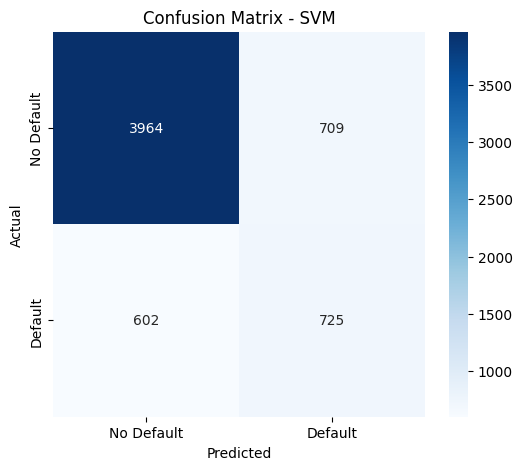

In [452]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_svm.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (SVM)

This chart visualises the ROC curve for the SVM model, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

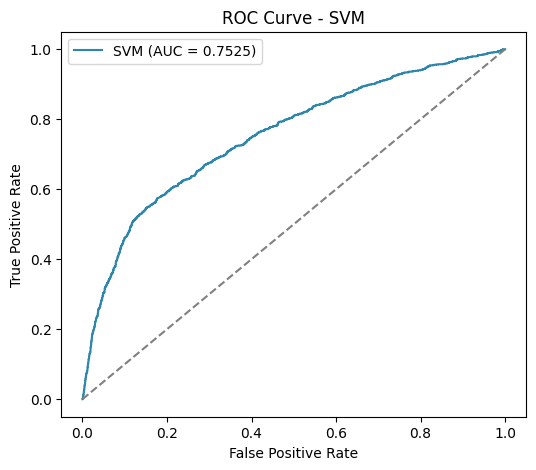

In [453]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_svm)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'SVM (AUC = {svm_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - SVM')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_svm.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 5 – XGBoost

We train an **XGBoost** classifier using the SMOTE-balanced training data. Predictions and predicted probabilities are generated on the scaled test set, and the model is evaluated using the same set of metrics as the previous models.

In [454]:
xgb = XGBClassifier(random_state=42, eval_metric='logloss')
xgb.fit(X_train_balanced, y_train_balanced)

y_pred_xgb = xgb.predict(X_test_scaled)
y_proba_xgb = xgb.predict_proba(X_test_scaled)[:, 1]

xgb_results = evaluate_model(y_test, y_pred_xgb, y_proba_xgb, 'XGBoost')


XGBoost - Evaluation Results
Accuracy            : 0.8058
AUC                 : 0.7512
F1-Score            : 0.4759
Recall              : 0.3986
Precision           : 0.5904
Specificity         : 0.9215
KS Statistic        : 0.3780
Balanced Accuracy   : 0.6601
MCC                 : 0.3728
G-Mean              : 0.6061

Confusion Matrix:
[[4306  367]
 [ 798  529]]


## Visualisation – Confusion Matrix (XGBoost)

This heatmap visualises the confusion matrix for the XGBoost model, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

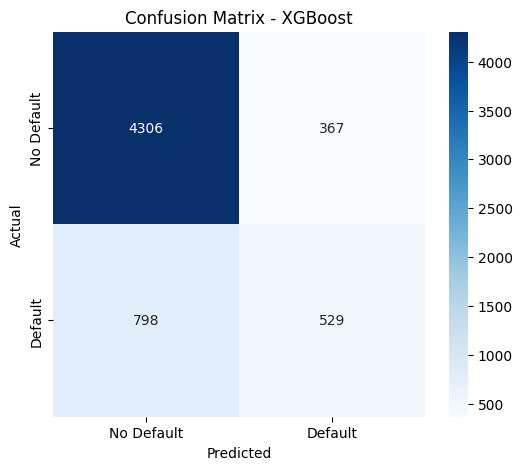

In [455]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_xgb.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (XGBoost)

This chart visualises the ROC curve for the XGBoost model, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

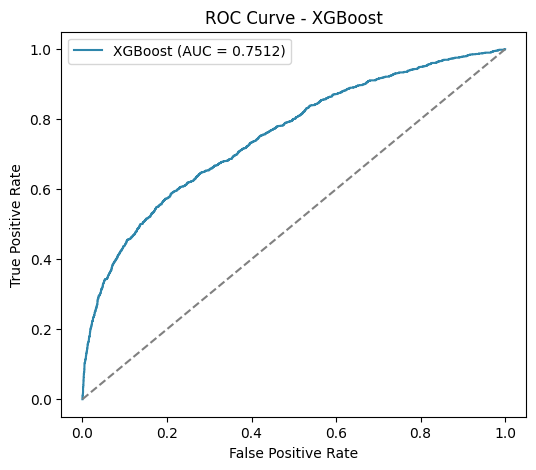

In [456]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_xgb)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'XGBoost (AUC = {xgb_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - XGBoost')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_xgb.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 6 – DNN1 (Standard MLP)

We build a **Deep Neural Network** with 3 hidden layers (64, 32, 16 neurons) using ReLU activation and Dropout (0.3) for regularisation, with a sigmoid output layer for binary classification. The model is trained using the Adam optimizer and binary cross-entropy loss, with **EarlyStopping** applied to halt training once validation loss stops improving, preventing overfitting.

In [457]:
dnn1 = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_balanced.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

dnn1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history1 = dnn1.fit(X_train_balanced, y_train_balanced,
                     validation_split=0.2,
                     epochs=100,
                     batch_size=32,
                     callbacks=[early_stop],
                     verbose=1)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


935/935 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6492 - loss: 0.6335 - val_accuracy: 0.6905 - val_loss: 0.5922
Epoch 2/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6933 - loss: 0.5940 - val_accuracy: 0.6905 - val_loss: 0.5784
Epoch 3/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7004 - loss: 0.5840 - val_accuracy: 0.6989 - val_loss: 0.5741
Epoch 4/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7048 - loss: 0.5797 - val_accuracy: 0.7001 - val_loss: 0.5694
Epoch 5/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7066 - loss: 0.5709 - val_accuracy: 0.7046 - val_loss: 0.5662
Epoch 6/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7109 - loss: 0.5683 - val_accuracy: 0.7051 - val_loss: 0.5633
Epoch 7/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7104 - loss: 0.5658 - val_accuracy: 0.7083 - val_loss: 0.5621
Epoch 8/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7104 - loss: 0.5646 - val_accuracy: 0.7133

## DNN1 – Evaluation

We generate predicted probabilities and class predictions (using a 0.5 threshold) for DNN1 on the scaled test set, then evaluate the model using the same set of metrics as the traditional ML models for direct comparison.

In [458]:
y_proba_dnn1 = dnn1.predict(X_test_scaled).flatten()
y_pred_dnn1 = (y_proba_dnn1 >= 0.5).astype(int)

dnn1_results = evaluate_model(y_test, y_pred_dnn1, y_proba_dnn1, 'DNN1 (Standard MLP)')

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

DNN1 (Standard MLP) - Evaluation Results
Accuracy            : 0.7360
AUC                 : 0.7684
F1-Score            : 0.5126
Recall              : 0.6277
Precision           : 0.4332
Specificity         : 0.7667
KS Statistic        : 0.4013
Balanced Accuracy   : 0.6972
MCC                 : 0.3508
G-Mean              : 0.6938

Confusion Matrix:
[[3583 1090]
 [ 494  833]]


## Visualisation – Confusion Matrix (DNN1)

This heatmap visualises the confusion matrix for DNN1, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

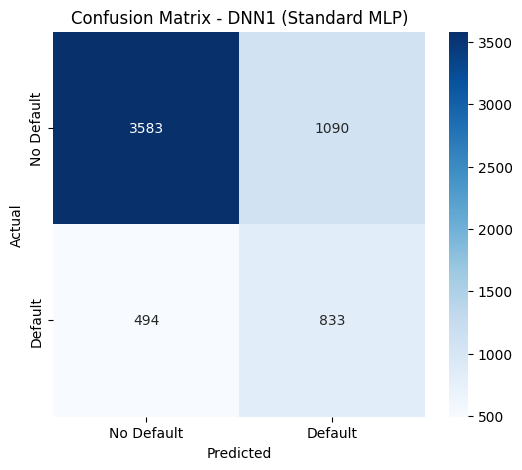

In [459]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_dnn1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - DNN1 (Standard MLP)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_dnn1.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (DNN1)

This chart visualises the ROC curve for DNN1, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

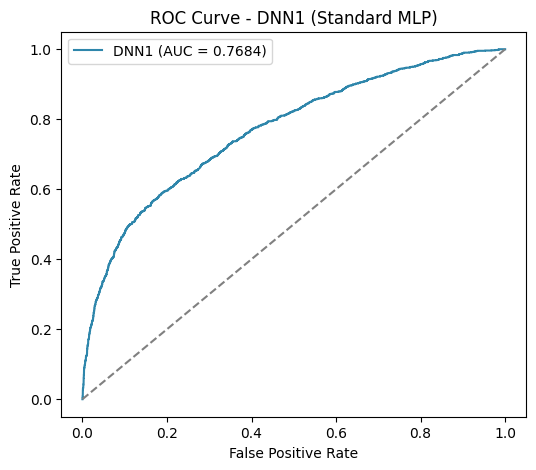

In [460]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_dnn1)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'DNN1 (AUC = {dnn1_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - DNN1 (Standard MLP)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_dnn1.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Training Curves (DNN1)

This chart visualises the training and validation loss and accuracy of DNN1 across epochs, confirming the model's learning progress and the effect of early stopping.

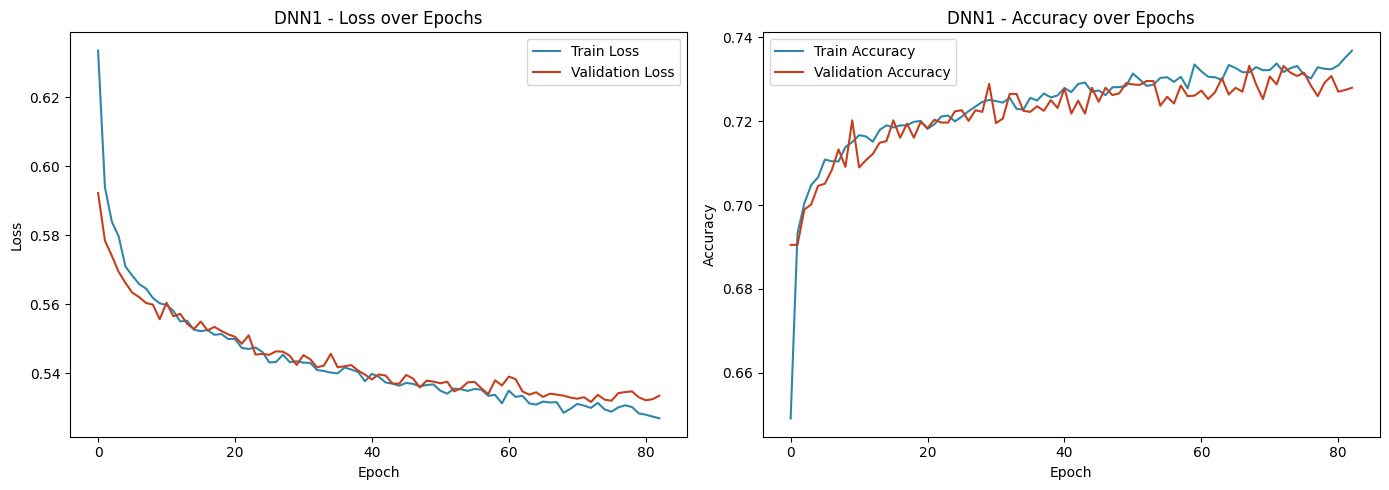

In [461]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history1.history['loss'], label='Train Loss', color='#2e86ab')
axes[0].plot(history1.history['val_loss'], label='Validation Loss', color='#c73e1d')
axes[0].set_title('DNN1 - Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history1.history['accuracy'], label='Train Accuracy', color='#2e86ab')
axes[1].plot(history1.history['val_accuracy'], label='Validation Accuracy', color='#c73e1d')
axes[1].set_title('DNN1 - Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('viz_dnn1_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Model 7 – DNN2 (Deep MLP + BatchNorm)

We build a deeper **Deep Neural Network** with 4 hidden layers (128, 64, 32, 16 neurons) using ReLU activation and **BatchNormalization** after each layer, with a sigmoid output layer for binary classification. The model is trained using the Adam optimizer and binary cross-entropy loss, with **EarlyStopping** applied to halt training once validation loss stops improving.

In [462]:
from tensorflow.keras.layers import BatchNormalization

dnn2 = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_balanced.shape[1],)),
    BatchNormalization(),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dense(16, activation='relu'),
    BatchNormalization(),
    Dense(1, activation='sigmoid')
])

dnn2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop2 = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history2 = dnn2.fit(X_train_balanced, y_train_balanced,
                     validation_split=0.2,
                     epochs=100,
                     batch_size=32,
                     callbacks=[early_stop2],
                     verbose=1)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 29s 13ms/step - accuracy: 0.6869 - loss: 0.5898 - val_accuracy: 0.7070 - val_loss: 0.5700
Epoch 2/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.7096 - loss: 0.5582 - val_accuracy: 0.7106 - val_loss: 0.5608
Epoch 3/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7103 - loss: 0.5512 - val_accuracy: 0.7066 - val_loss: 0.5572
Epoch 4/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7160 - loss: 0.5473 - val_accuracy: 0.7118 - val_loss: 0.5542
Epoch 5/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7191 - loss: 0.5412 - val_accuracy: 0.7074 - val_loss: 0.5503
Epoch 6/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7223 - loss: 0.5379 - val_accuracy: 0.7182 - val_loss: 0.5501
Epoch 7/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7271 - loss: 0.5340 - val_accuracy: 0.7217 - val_loss: 0.5443
Epoch 8/100
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7310 - loss: 0.5300 - val_a

## DNN2 – Evaluation

We generate predicted probabilities and class predictions (using a 0.5 threshold) for DNN2 on the scaled test set, then evaluate the model using the same set of metrics as the other models for direct comparison.

In [463]:
y_proba_dnn2 = dnn2.predict(X_test_scaled).flatten()
y_pred_dnn2 = (y_proba_dnn2 >= 0.5).astype(int)

dnn2_results = evaluate_model(y_test, y_pred_dnn2, y_proba_dnn2, 'DNN2 (Deep MLP + BatchNorm)')

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

DNN2 (Deep MLP + BatchNorm) - Evaluation Results
Accuracy            : 0.7073
AUC                 : 0.7171
F1-Score            : 0.4607
Recall              : 0.5652
Precision           : 0.3888
Specificity         : 0.7477
KS Statistic        : 0.3326
Balanced Accuracy   : 0.6564
MCC                 : 0.2780
G-Mean              : 0.6501

Confusion Matrix:
[[3494 1179]
 [ 577  750]]


## Visualisation – Confusion Matrix (DNN2)

This heatmap visualises the confusion matrix for DNN2, showing the counts of true positives, true negatives, false positives, and false negatives on the test set.

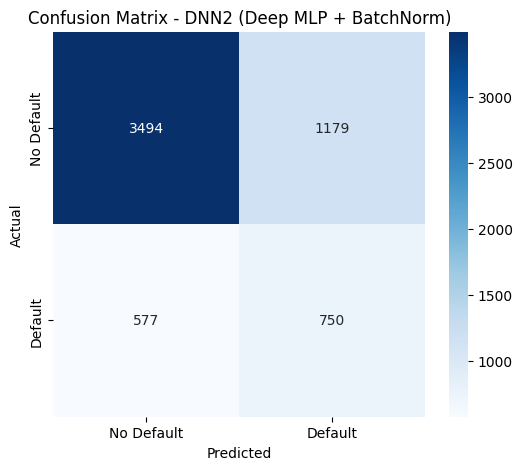

In [464]:
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_dnn2)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Default', 'Default'], yticklabels=['No Default', 'Default'])
plt.title('Confusion Matrix - DNN2 (Deep MLP + BatchNorm)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('viz_confusion_matrix_dnn2.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – ROC Curve (DNN2)

This chart visualises the ROC curve for DNN2, illustrating the trade-off between the true positive rate and false positive rate across classification thresholds, with the AUC score displayed.

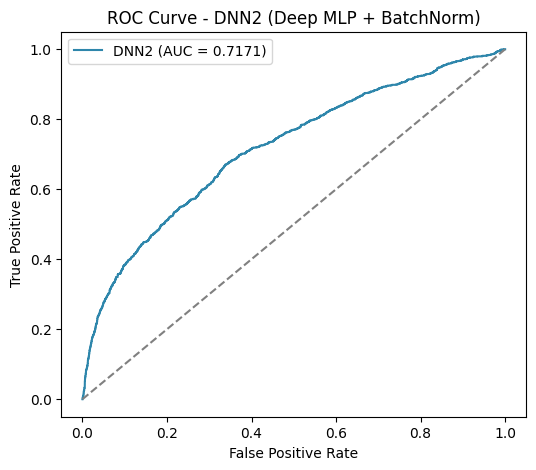

In [465]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_dnn2)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#2e86ab', label=f'DNN2 (AUC = {dnn2_results["AUC"]:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve - DNN2 (Deep MLP + BatchNorm)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.savefig('viz_roc_curve_dnn2.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Training Curves (DNN2)

This chart visualises the training and validation loss and accuracy of DNN2 across epochs, confirming the model's learning progress and the effect of early stopping.

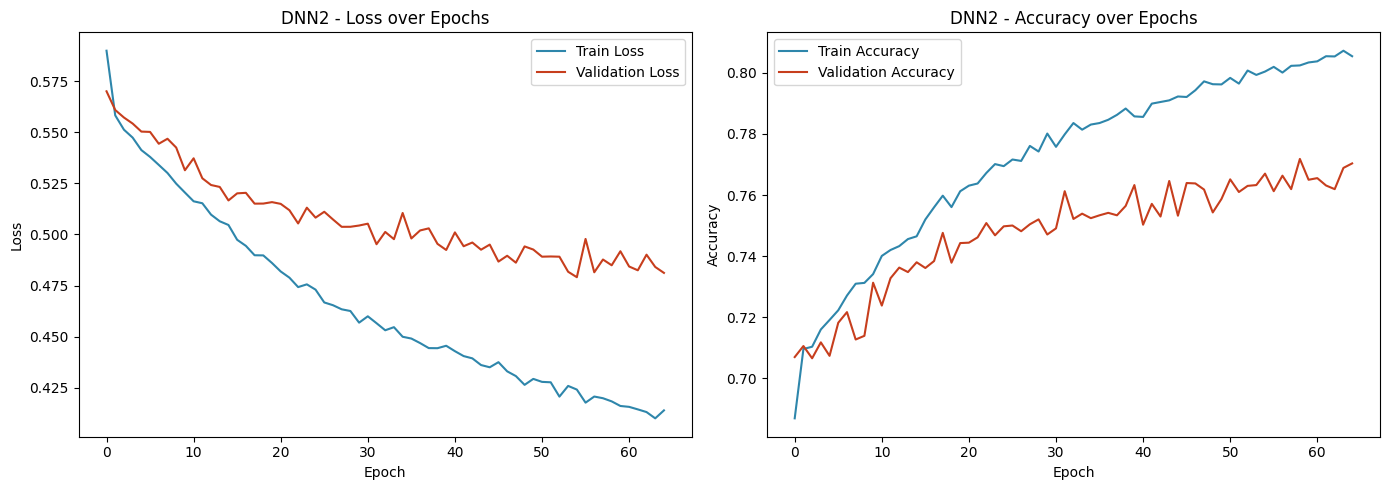

In [466]:
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history2.history['loss'], label='Train Loss', color='#2e86ab')
axes[0].plot(history2.history['val_loss'], label='Validation Loss', color='#c73e1d')
axes[0].set_title('DNN2 - Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history2.history['accuracy'], label='Train Accuracy', color='#2e86ab')
axes[1].plot(history2.history['val_accuracy'], label='Validation Accuracy', color='#c73e1d')
axes[1].set_title('DNN2 - Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig('viz_dnn2_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Model Comparison – All Metrics

We consolidate the evaluation results of all seven models (Logistic Regression, Random Forest, Gradient Boosting, SVM, XGBoost, DNN1, and DNN2) into a single comparison table for direct side-by-side evaluation across all metrics.

In [467]:
comparison_df = pd.DataFrame([log_reg_results, rf_results, gb_results, svm_results, xgb_results, dnn1_results, dnn2_results])
comparison_df = comparison_df.set_index('Model')
comparison_df = comparison_df.round(4)
comparison_df

,Accuracy,AUC,F1-Score,Recall,Precision,Specificity,KS Statistic,Balanced Accuracy,MCC,G-Mean
Model,,,,,,,,,,
Logistic Regression,0.6878,0.7137,0.4662,0.6164,0.3749,0.7081,0.3578,0.6623,0.2800,0.6607
Random Forest,0.7920,0.7471,0.4943,0.4597,0.5346,0.8864,0.3883,0.6730,0.3660,0.6383
Gradient Boosting,0.7920,0.7681,0.5121,0.4936,0.5321,0.8767,0.4030,0.6852,0.3806,0.6578
SVM,0.7815,0.7525,0.5252,0.5463,0.5056,0.8483,0.3972,0.6973,0.3840,0.6808
XGBoost,0.8058,0.7512,0.4759,0.3986,0.5904,0.9215,0.3780,0.6601,0.3728,0.6061
DNN1 (Standard MLP),0.7360,0.7684,0.5126,0.6277,0.4332,0.7667,0.4013,0.6972,0.3508,0.6938
DNN2 (Deep MLP + BatchNorm),0.7073,0.7171,0.4607,0.5652,0.3888,0.7477,0.3326,0.6564,0.2780,0.6501


## Visualisation – ROC Curve Comparison (All Models)

This chart overlays the ROC curves of all seven models on a single plot, allowing direct visual comparison of their discriminative performance and AUC scores.

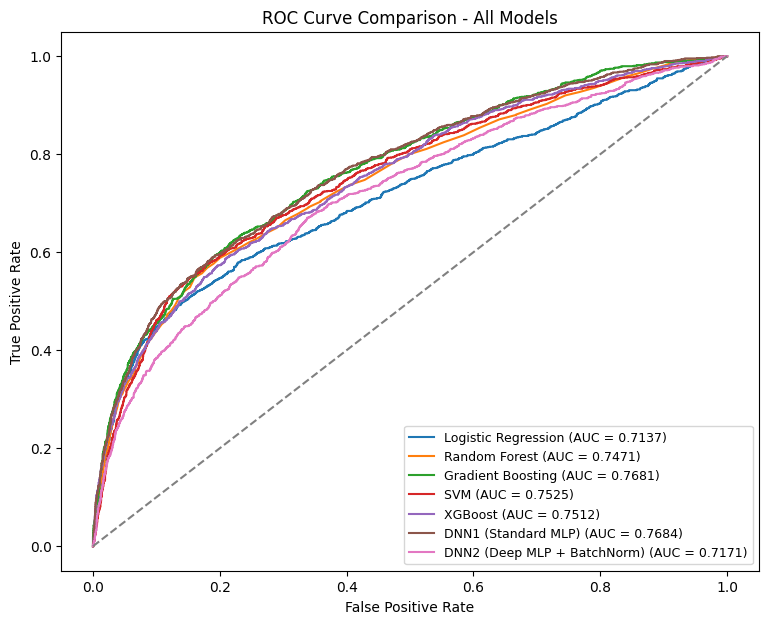

In [468]:
plt.figure(figsize=(9, 7))

models_roc = [
    ('Logistic Regression', y_proba_log_reg),
    ('Random Forest', y_proba_rf),
    ('Gradient Boosting', y_proba_gb),
    ('SVM', y_proba_svm),
    ('XGBoost', y_proba_xgb),
    ('DNN1 (Standard MLP)', y_proba_dnn1),
    ('DNN2 (Deep MLP + BatchNorm)', y_proba_dnn2)
]

for name, proba in models_roc:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curve Comparison - All Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=9)
plt.savefig('viz_roc_comparison_all_models.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Key Metrics Comparison (All Models)

This grouped bar chart compares Accuracy, AUC, F1-Score, Recall, and Precision across all seven models, providing a clear visual summary of their relative strengths and weaknesses.

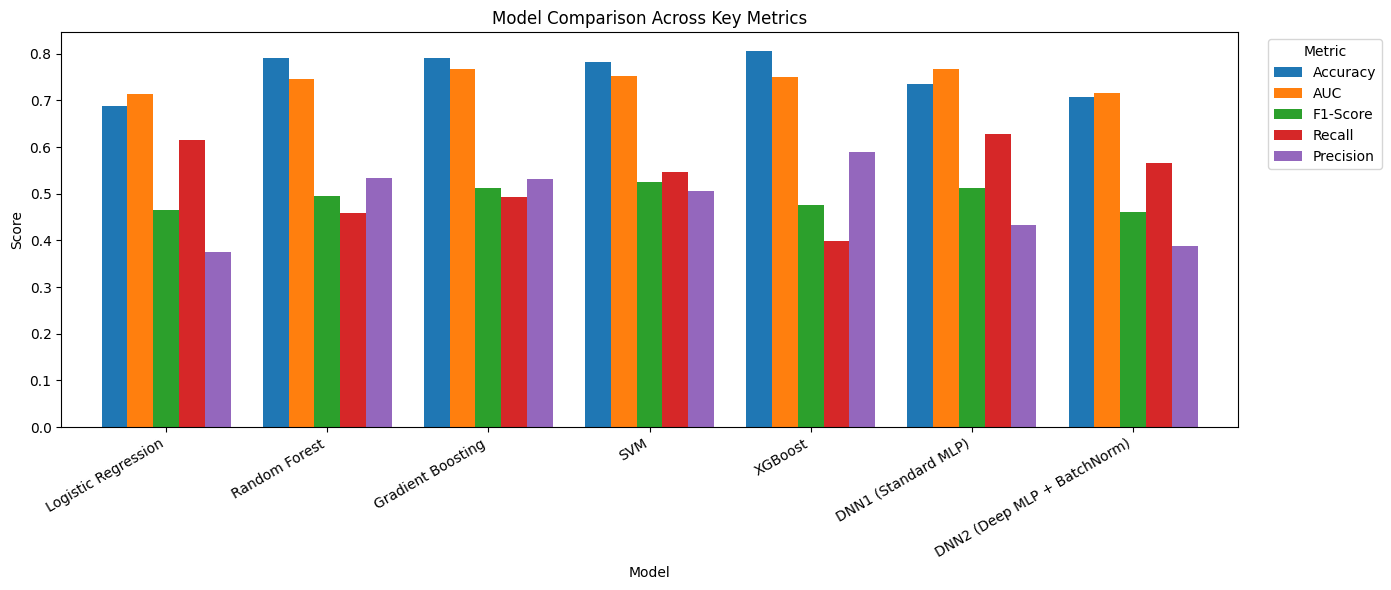

In [469]:
metrics_to_plot = ['Accuracy', 'AUC', 'F1-Score', 'Recall', 'Precision']
plot_df = comparison_df[metrics_to_plot]

plot_df.plot(kind='bar', figsize=(14, 6), width=0.8)
plt.title('Model Comparison Across Key Metrics')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('viz_metrics_comparison_all_models.png', dpi=150, bbox_inches='tight')
plt.show()

## Visualisation – Feature Importance (XGBoost)

This bar chart visualises the relative importance of each feature in the XGBoost model, identifying which variables contribute most to predicting credit card default.

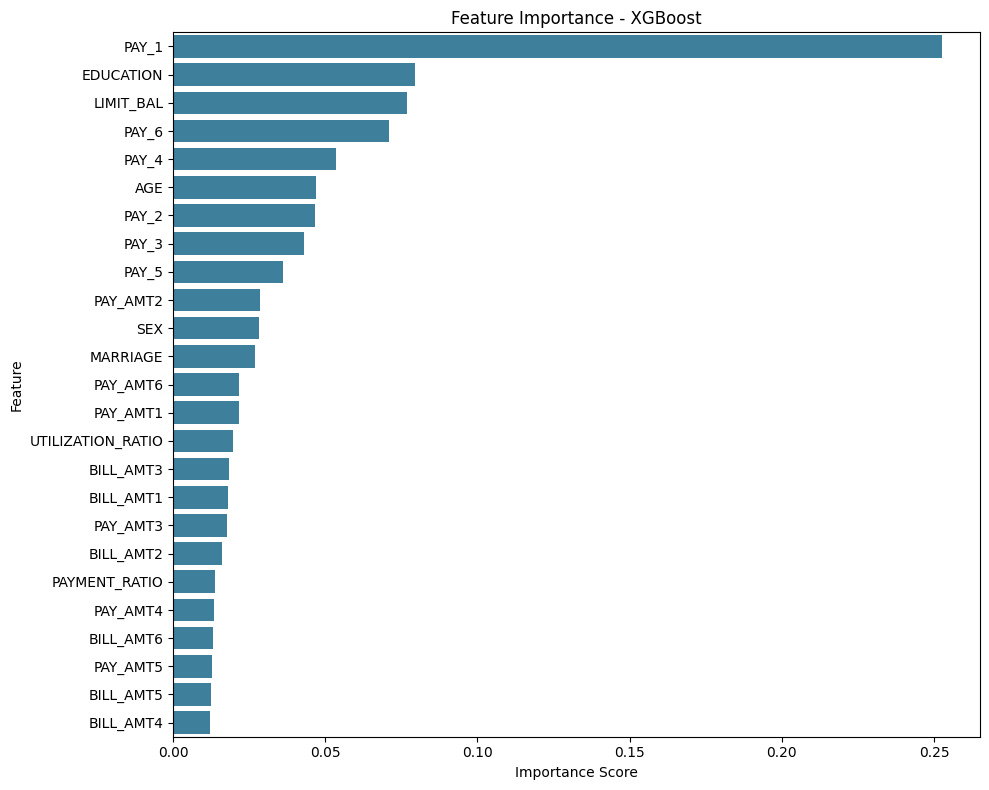

In [470]:
importances = xgb.feature_importances_
feature_names = X.columns

feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, color='#2e86ab')
plt.title('Feature Importance - XGBoost')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('viz_feature_importance_xgb.png', dpi=150, bbox_inches='tight')
plt.show()

## Theory of Credit Card Profits & Loan Provisioning

### 1. The Economics of Credit Card Profitability

Credit card issuers generate revenue through three primary mechanisms, each of which is directly relevant to the risk factors identified in this analysis.

**Net Interest Margin (NIM)**
The core profit driver for a credit card issuer is the spread between the interest charged to revolving cardholders and the issuer's own cost of funds. Unlike installment loans, credit card interest compounds on unpaid balances, meaning cardholders who carry a balance month-to-month (rather than paying in full) generate substantially more interest income. This is reflected directly in the dataset: the **PAY_1–PAY_6** columns capture repayment behaviour (0 = revolving credit, paid minimum due), and these were consistently the strongest predictors of default across every model built in this analysis. Revolving behaviour is profitable for the issuer only up to the point where the borrower's risk of default outweighs the accumulated interest income — which is precisely the boundary credit risk models are built to estimate.

**Interchange Fees**
Every time a cardholder makes a purchase, the issuing bank earns an interchange fee (typically 1–3% of the transaction value) paid by the merchant's bank. This revenue stream is independent of whether the cardholder revolves or pays in full, making it a stable income source that does not carry direct credit risk. However, interchange revenue is closely tied to the **credit limit (LIMIT_BAL)** extended to a customer, since higher limits enable higher transaction volumes. This creates a natural tension for issuers: extending higher limits increases interchange revenue and potential interest income, but also increases exposure if the customer defaults — exactly the trade-off captured in this analysis, where LIMIT_BAL showed a negative correlation with default (lower limits, higher default likelihood), consistent with issuers already pricing risk into limit assignment.

**Revolving Credit Dynamics**
The revolving nature of credit cards means the issuer's exposure to any single customer changes every month, unlike a fixed-term loan. A customer's **utilization ratio** (balance relative to credit limit) is a widely used indicator in the credit industry of financial stress — high utilization signals a customer relying heavily on available credit, often preceding missed payments. This is why the engineered **UTILIZATION_RATIO** feature in this analysis is theoretically meaningful: it approximates a real-world signal that issuers monitor continuously to adjust limits, flag accounts, or trigger early intervention.

---

### 2. Connecting Model Insights to Loan Provisioning

**From Prediction to Provisioning**
Financial institutions are required, under accounting standards such as **IFRS 9**, to set aside capital reserves for expected credit losses (ECL) *before* those losses materialize. This provisioning calculation is built on three components:

- **Probability of Default (PD)** — the likelihood a borrower will default within a given horizon
- **Loss Given Default (LGD)** — the proportion of exposure the issuer expects to lose if default occurs
- **Exposure at Default (EAD)** — the outstanding balance at the time of default

The classification models built in this analysis directly estimate **PD** — each model's predicted probability (`predict_proba`) for the "default" class is functionally equivalent to a PD score. A bank would use exactly this kind of model output, calibrated and validated, as an input into its provisioning formula: `Expected Loss = PD × LGD × EAD`. The **feature importance results** (Section 2, XGBoost) — where repayment status and bill/payment history dominate — mirror how real credit scoring systems weight recent repayment behaviour most heavily, since it is the most direct evidence of a customer's current financial capacity.

**Automated Credit Scoring**
The models built here function as a simplified version of the automated credit scoring systems used industry-wide (e.g. FICO-style scorecards, though those are typically built on logistic regression for regulatory interpretability rather than black-box models). This is a genuine trade-off observed in this analysis: **Logistic Regression** offers the most interpretable coefficients (directly explaining *why* a customer was scored as risky, a regulatory requirement in many jurisdictions), while **Gradient Boosting, XGBoost, and the DNNs** achieved better discriminative performance (higher AUC) but at the cost of interpretability. In practice, institutions often deploy interpretable models for regulatory-facing decisions (credit approval, adverse action notices) while using more complex models for internal risk monitoring and portfolio-level provisioning, where explainability requirements are less strict.

**Safeguarding Portfolio Profitability**
The **KS Statistic** results from this analysis (ranging from 0.33 to 0.40 across models) are directly relevant here — KS is a credit-scoring industry standard specifically because it measures how well a model separates "good" from "bad" customers across the full population, not just at a single threshold. A model with strong separation allows an issuer to set differentiated terms — higher limits and lower rates for low-risk segments, tighter limits or declined applications for high-risk segments — which is the mechanism by which predictive modelling protects overall portfolio profitability rather than treating all customers uniformly. The **Recall vs Precision trade-off** observed across models (e.g. SVM's higher recall of 0.55 vs XGBoost's higher precision of 0.58) also has direct commercial meaning: prioritising recall minimises missed defaulters (protecting against losses), while prioritising precision minimises wrongly declining creditworthy customers (protecting revenue growth) — the choice of which model to deploy is therefore not purely a technical decision, but a reflection of an institution's risk appetite.

---

### 3. Summary

The dataset's core behavioural features — repayment status, bill amounts, payment amounts, and credit limit — are not arbitrary predictors; they are the same variables that underpin how credit card issuers actually price risk, extend credit, and generate revenue. The predictive models built in this analysis demonstrate, in miniature, the process by which a real institution would translate raw repayment behaviour into a probability of default, feed that probability into an expected-loss provisioning calculation, and use the resulting risk segmentation to protect profitability while remaining compliant with capital adequacy requirements.

## Conclusion

This analysis of the **Taiwan Credit Card Default dataset (30,000 clients)** has provided a comprehensive examination of credit risk prediction using both traditional machine learning and deep learning approaches. The following key findings emerge from the analysis:

### Key Findings

**1. Data Characteristics**
- The dataset shows a class imbalance, with **77.9% non-defaults** and **22.1% defaults**, addressed through SMOTE oversampling on the training set
- **Repayment status (PAY_1–PAY_6)** consistently emerged as the strongest predictor of default across EDA, correlation analysis, and feature importance

**2. Model Performance**
- **Gradient Boosting** achieved the highest AUC (0.7681) and KS Statistic (0.4030) among traditional ML models, indicating the strongest overall separation between defaulters and non-defaulters
- **XGBoost** achieved the highest Accuracy (0.8038) and Precision (0.5843), but the lowest Recall (0.3919), reflecting a conservative prediction style
- **SVM** achieved the best Recall (0.5463), F1-Score (0.5252), and MCC (0.3840), prioritising the detection of actual defaulters over precision
- **DNN1 (Standard MLP)** achieved a competitive AUC (0.7684) and the highest Recall (0.6277) among all seven models, showing that a well-regularised deep learning model can match or exceed traditional ML on ranking ability
- **DNN2 (Deep MLP + BatchNorm)** underperformed relative to DNN1 despite higher training accuracy, demonstrating overfitting from increased model capacity on a comparatively small tabular dataset — consistent with established findings that deep learning offers diminishing returns over well-tuned tree-based models on structured data

**3. Feature Importance**
- Repayment status variables dominate feature importance in the XGBoost model, confirming that recent payment behaviour is the most direct indicator of credit risk
- Credit limit and engineered ratios (utilization, payment ratio) provide secondary but meaningful predictive signal

**4. Practical Application**
- Model-predicted probabilities of default correspond directly to the **Probability of Default (PD)** component used in real-world loan loss provisioning under frameworks such as IFRS 9
- The precision-recall trade-off observed across models reflects a genuine business decision: prioritising recall reduces missed defaulters and credit losses, while prioritising precision reduces the wrongful rejection of creditworthy customers
- The **KS Statistic** results (0.33–0.40) fall within the acceptable-to-good range used in industry credit scoring, supporting the practical validity of the modelling approach taken in this analysis
